In [4]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_squared_error

from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso

from tqdm import tqdm

# Data Cleaning

In [7]:
# data_root = Path("data")
data_root = Path(".")

In [9]:
unemp = pd.read_csv(data_root / "unemp.csv")
unemp

,DATE,LRUNTTTTCAM156S
0,2004-01-01,7.3
1,2004-02-01,7.3
2,2004-03-01,7.3
3,2004-04-01,7.2
4,2004-05-01,7.1
...,...,...
175,2018-08-01,6.0
176,2018-09-01,5.8
177,2018-10-01,5.7
178,2018-11-01,5.7


In [10]:
unemp.columns = ["Date", "Unemployment"]

In [11]:
unemp.dtypes

Date             object
Unemployment    float64
dtype: object

In [12]:
unemp["Date"] = unemp["Date"].apply(pd.to_datetime)
unemp.set_index("Date", inplace=True)
unemp

,Unemployment
Date,
2004-01-01,7.3
2004-02-01,7.3
2004-03-01,7.3
2004-04-01,7.2
2004-05-01,7.1
...,...
2018-08-01,6.0
2018-09-01,5.8
2018-10-01,5.7


In [13]:
unemp.index

DatetimeIndex(['2004-01-01', '2004-02-01', '2004-03-01', '2004-04-01',
               '2004-05-01', '2004-06-01', '2004-07-01', '2004-08-01',
               '2004-09-01', '2004-10-01',
               ...
               '2018-03-01', '2018-04-01', '2018-05-01', '2018-06-01',
               '2018-07-01', '2018-08-01', '2018-09-01', '2018-10-01',
               '2018-11-01', '2018-12-01'],
              dtype='datetime64[ns]', name='Date', length=180, freq=None)

In [14]:
trend_files = data_root.glob("multiTimeline*.csv")
trend_files

<generator object Path.glob at 0x0000012828FBBEF0>

In [15]:
dfs = list()
for trend_file in trend_files:
    df = (
        pd.read_csv(trend_file,
                    skiprows=1,
                    converters={"Month": pd.to_datetime})
        .rename({"Month": "Date"}, axis=1)
        .rename(lambda colname: colname.replace(": (Canada)", ''), axis=1)
        .set_index("Date")
    )
    dfs.append(df)
df = pd.concat(dfs, axis=1)
del dfs # remove unnecessary dataframes
df

,jobs
Date,
2004-01-01,47
2004-02-01,48
2004-03-01,49
2004-04-01,49
2004-05-01,48
...,...
2018-08-01,71
2018-09-01,69
2018-10-01,70


In [16]:
trend = unemp.join(df, how="inner")
del unemp
del df
trend

,Unemployment,jobs
Date,,
2004-01-01,7.3,47
2004-02-01,7.3,48
2004-03-01,7.3,49
2004-04-01,7.2,49
2004-05-01,7.1,48
...,...,...
2018-08-01,6.0,71
2018-09-01,5.8,69
2018-10-01,5.7,70


## Quick Visualization

In [17]:
target = "Unemployment"

In [18]:
# normalize data
trend_norm = (trend - trend.mean()) / trend.std()
trend_norm.mean(), trend_norm.std()

(Unemployment   -2.121760e-15
 jobs            1.578984e-16
 dtype: float64,
 Unemployment    1.0
 jobs            1.0
 dtype: float64)

In [19]:
trend_norm

,Unemployment,jobs
Date,,
2004-01-01,0.425400,-0.951665
2004-02-01,0.425400,-0.880498
2004-03-01,0.425400,-0.809331
2004-04-01,0.286933,-0.809331
2004-05-01,0.148467,-0.880498
...,...,...
2018-08-01,-1.374665,0.756350
2018-09-01,-1.651597,0.614016
2018-10-01,-1.790064,0.685183


<Axes: xlabel='Date'>

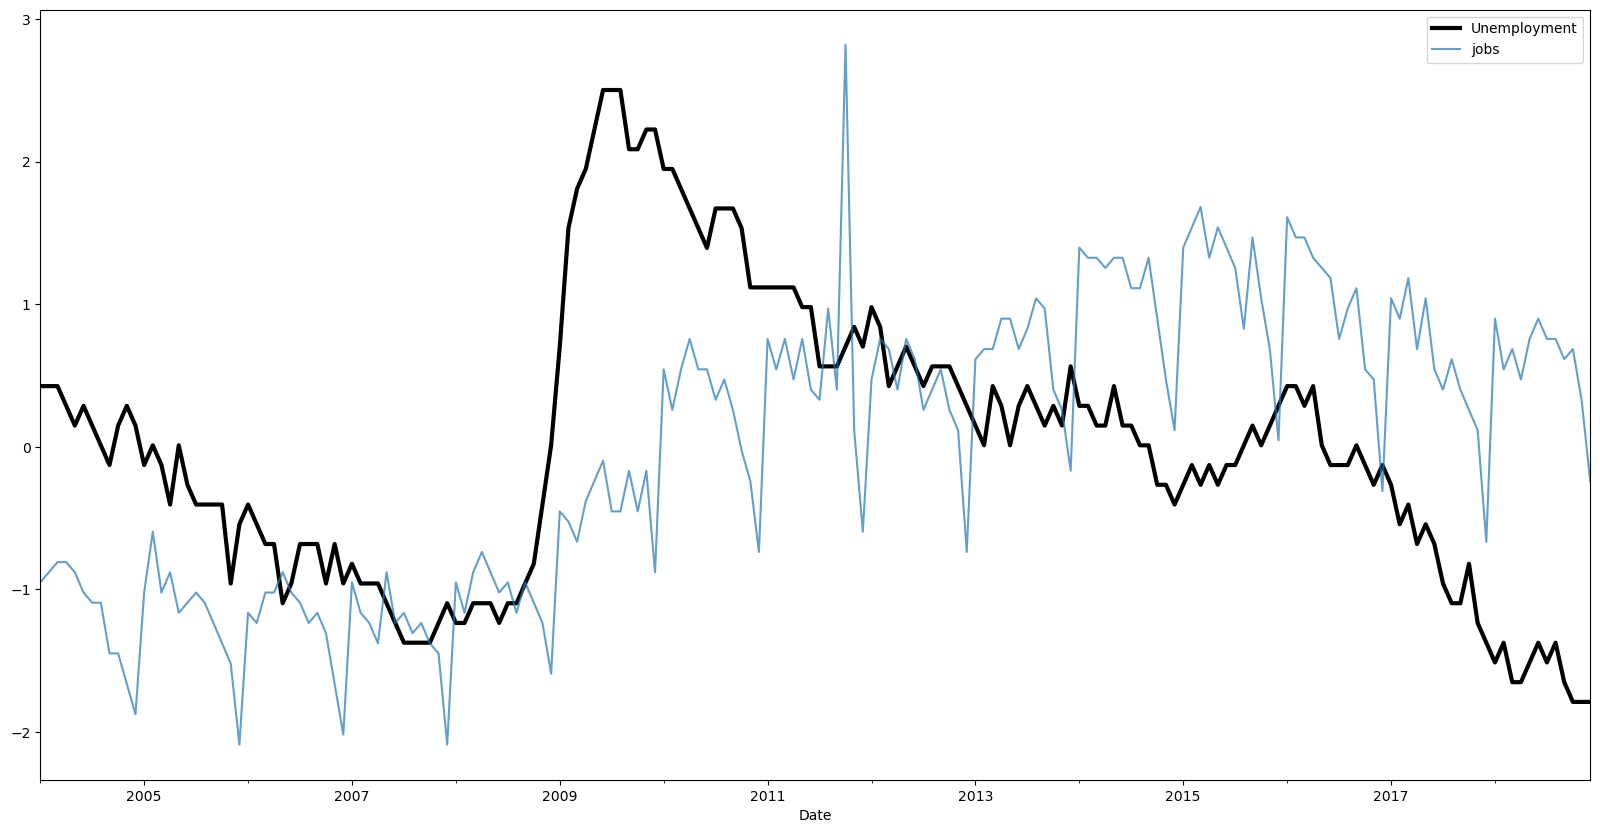

In [20]:
ax = trend_norm[[target]].plot(c="black", lw=3)
trend_norm.drop(target, axis=1).plot(alpha=0.7, figsize=(20,10), ax=ax)

# Model Training

In [66]:
def mse_gs_cv(model, params, X, y, cv=None):
    grid_search = GridSearchCV(model, params, cv=cv, scoring="neg_mean_squared_error")
    grid_search.fit(X, y)
    res = grid_search.cv_results_
    return pd.DataFrame(
        {p_name: res[f"param_{p_name}"].data for p_name in params.keys()}
        | {"score": res["mean_test_score"]}
    ), grid_search

def sort_lists(lists, based_on=0):
    return zip(*sorted(zip(*lists), key=lambda pair: pair[based_on]))

In [67]:
# add lag unemployment and drop first n rows
l = 1
trend_norm["Lag Unemployment"] = trend_norm[target].shift(l)
trend_norm = trend_norm.iloc[l:,:]
trend = trend.iloc[l:,:]

In [68]:
feats_to_drop = [target] + ["Lag Unemployment"]

feature_names = trend_norm.drop(feats_to_drop, axis=1).columns

X = trend_norm.drop(feats_to_drop, axis=1).values
y = trend[target].values

In [69]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

In [70]:
# How good/bad is the mean?
mean_squared_error(y_test, np.full(len(y_test), y_train.mean()))

0.5441418732782369

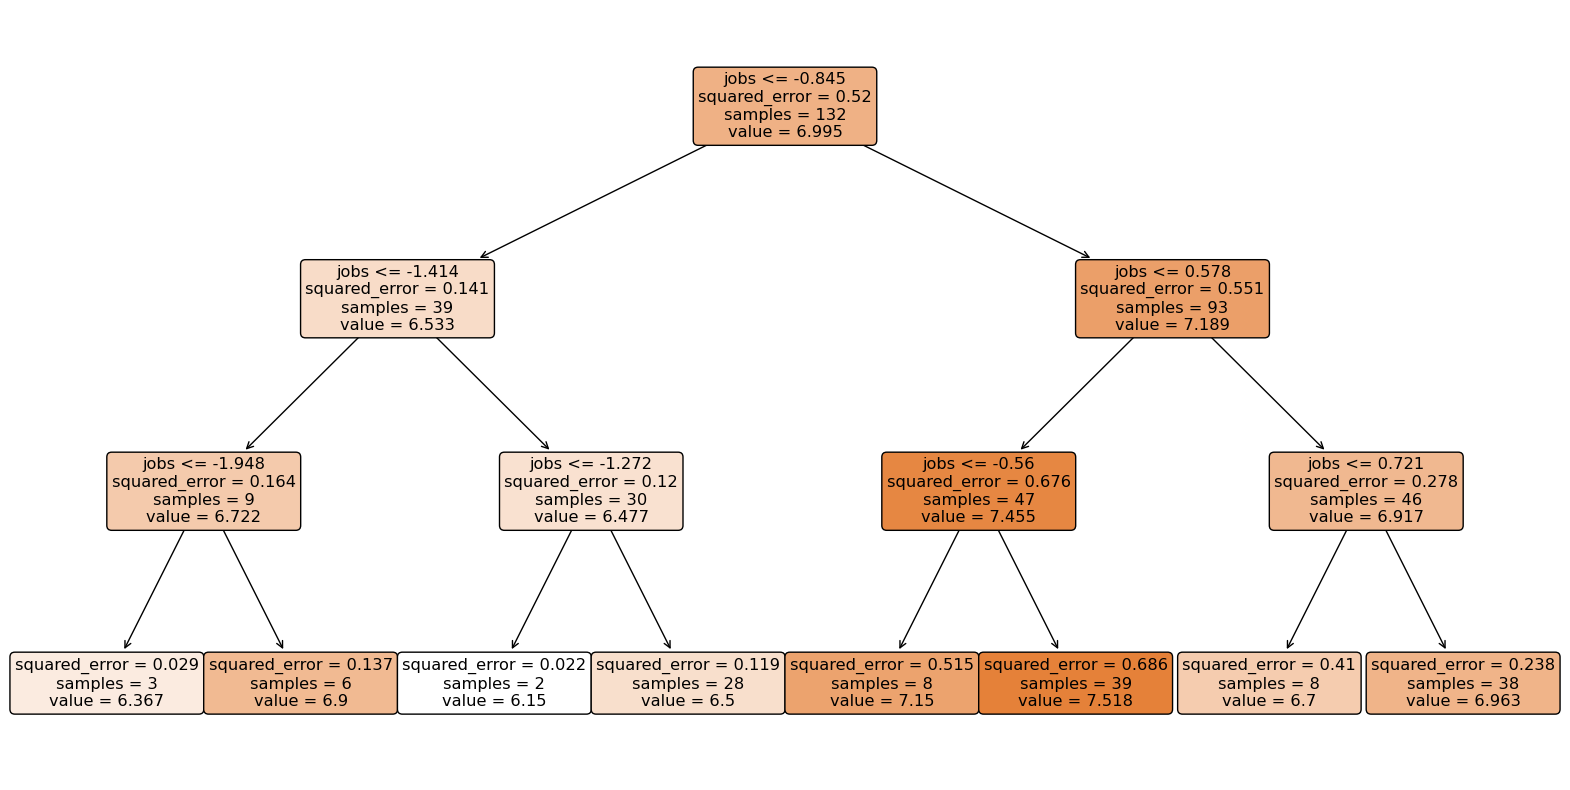

In [71]:
# 3a
matplotlib.rcParams['figure.figsize'] = (20, 10)
dtree = DecisionTreeRegressor(max_depth=3)
dtree.fit(X_train, y_train)
_ = plot_tree(dtree,
              feature_names=list(feature_names),
              filled=True, rounded=True)

In [72]:
mean_squared_error(y_test, dtree.predict(X_test))

0.4612543823224626

<BarContainer object of 1 artists>

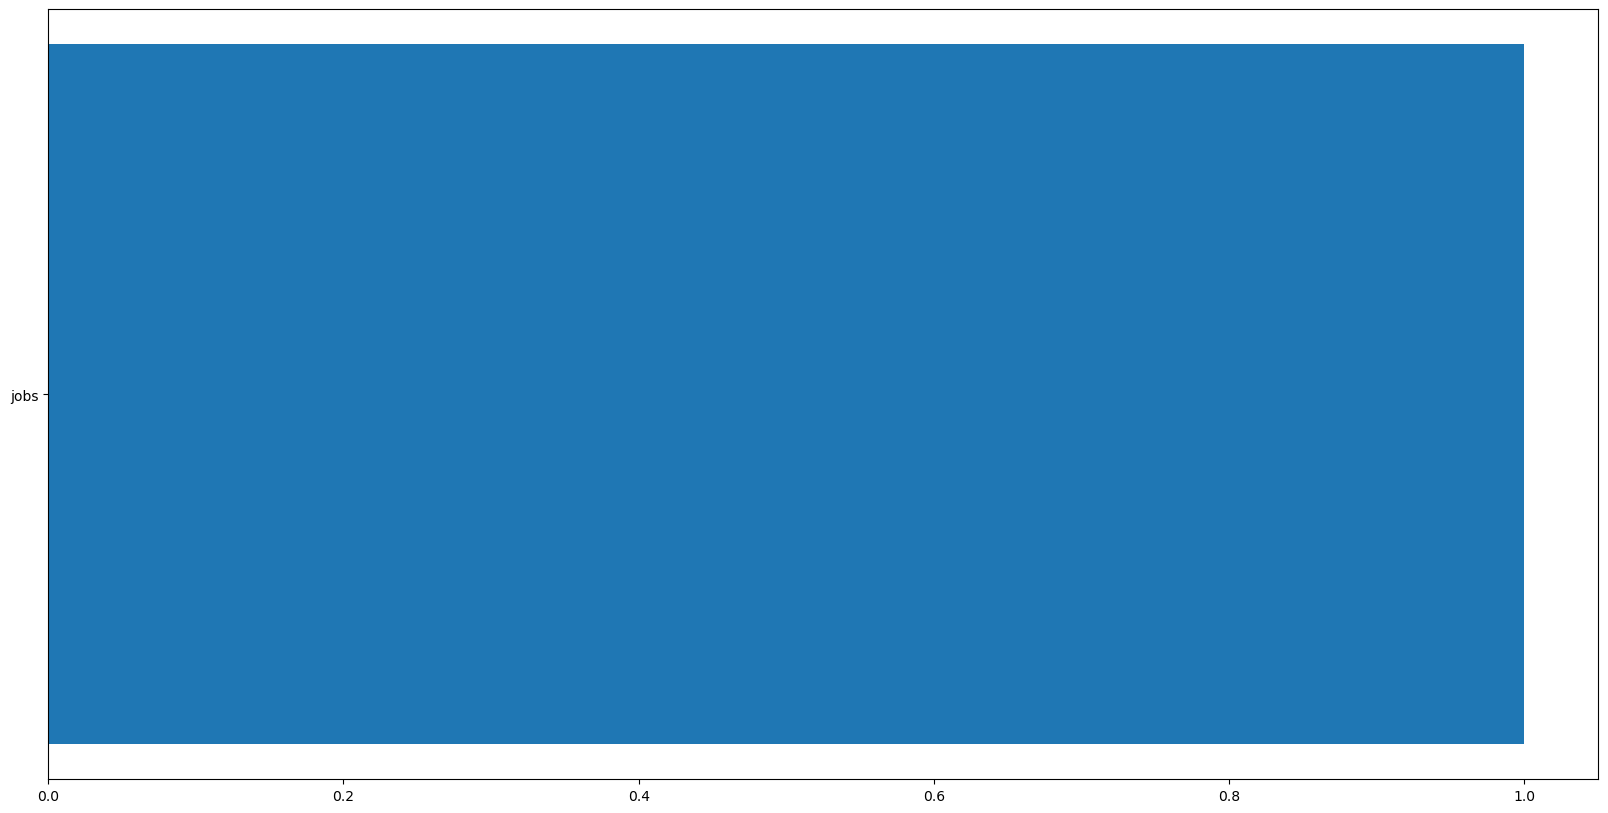

In [73]:
# 3b
rforest = RandomForestRegressor(max_depth=2)
rforest.fit(X_train, y_train)
simportances, snames = sort_lists([rforest.feature_importances_, feature_names])
plt.barh(snames, simportances)

In [74]:
mean_squared_error(y_test, rforest.predict(X_test))

0.422416428714034

<BarContainer object of 1 artists>

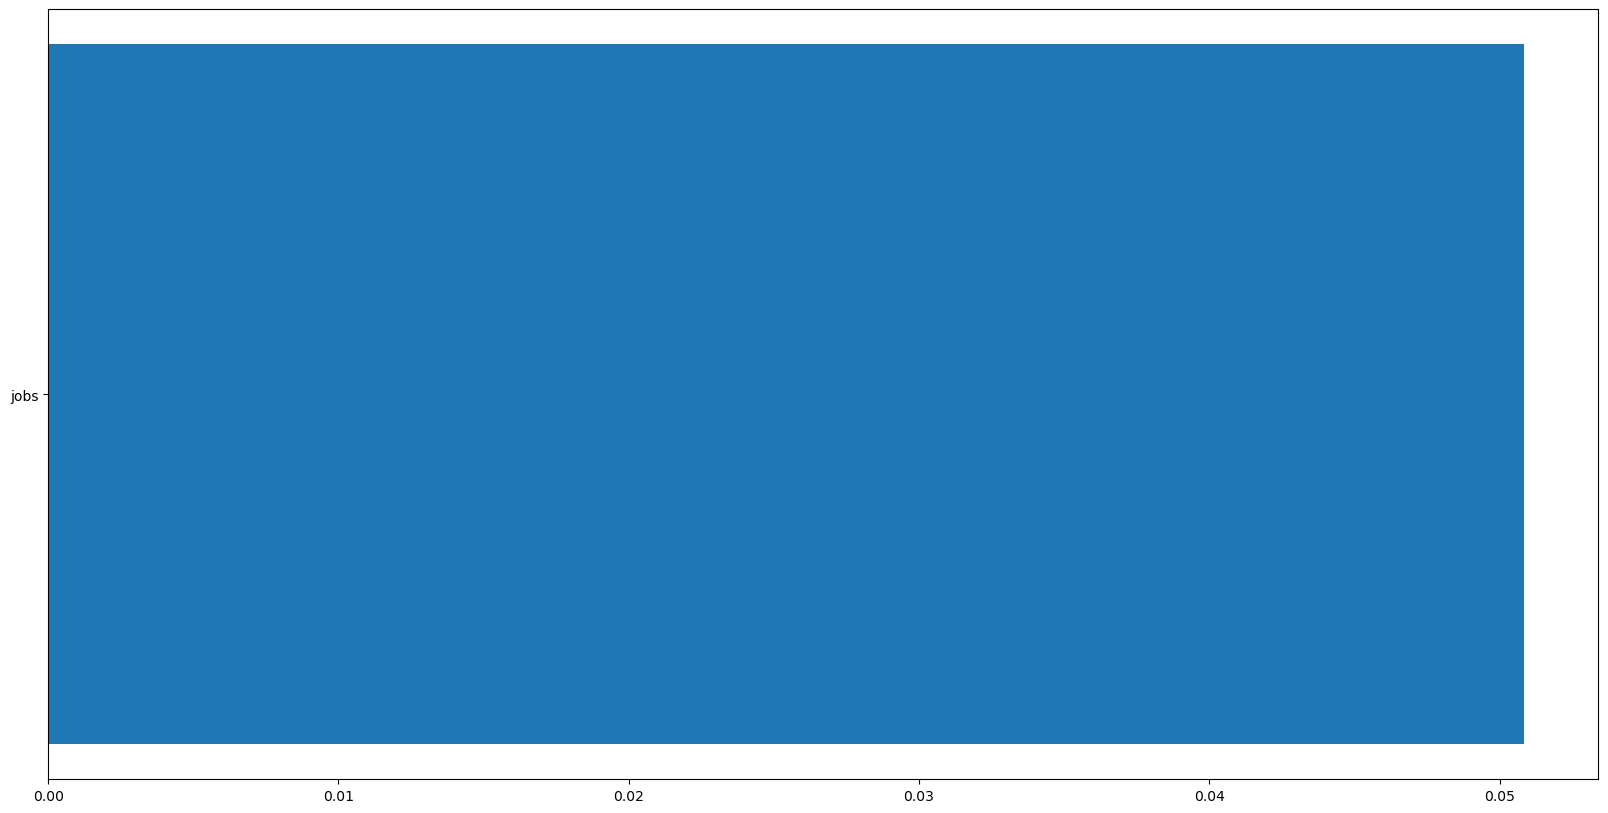

In [75]:
# 3c
rlin = Lasso(alpha=0.1)
rlin.fit(X_train, y_train)
coefs, cnames = sort_lists([rlin.coef_, feature_names])
plt.barh(cnames, coefs)

In [76]:
mean_squared_error(y_test, rlin.predict(X_test))

0.5273804922133967

In [77]:
# 4a

warnings.filterwarnings('ignore')

# CCP stands for Cost Complexity Pruning
models = [
    (dtree, "ccp_alpha", {"max_depth": 3}),
    (rforest, "ccp_alpha", {"max_depth": 2}),
    (rlin, "alpha", {}),
]

splitter = TimeSeriesSplit(n_splits=5, test_size=20, gap=2)
alpha_vals = [0] + list(0.25*(2**np.arange(8)))

dfs = []
for (model, alpha_name, default_params) in tqdm(models):
    df, gs = mse_gs_cv(model, {alpha_name: alpha_vals}, X, y, cv=splitter)
    df.rename({"ccp_alpha": "alpha"}, axis=1, inplace=True)
    df["model"] = type(model).__name__
    dfs.append(df)

df = pd.concat(dfs, axis=0)
del dfs
df

100%|████████████████████████████████████████████████████████████████████████████████████| 3/3 [00:15<00:00,  5.25s/it]


,alpha,score,model
0,0,-0.786275,DecisionTreeRegressor
1,0.25,-0.617626,DecisionTreeRegressor
2,0.5,-0.388870,DecisionTreeRegressor
3,1.0,-0.392935,DecisionTreeRegressor
4,2.0,-0.392935,DecisionTreeRegressor
5,4.0,-0.392935,DecisionTreeRegressor
6,8.0,-0.392935,DecisionTreeRegressor
7,16.0,-0.392935,DecisionTreeRegressor
8,32.0,-0.392935,DecisionTreeRegressor
0,0,-0.768142,RandomForestRegressor


In [78]:
df.pivot(index="alpha", columns="model", values="score")

model,DecisionTreeRegressor,Lasso,RandomForestRegressor
alpha,,,
0,-0.786275,-0.921812,-0.768142
0.25,-0.617626,-0.380716,-0.631228
0.5,-0.388870,-0.392935,-0.323156
1.0,-0.392935,-0.392935,-0.391199
2.0,-0.392935,-0.392935,-0.398259
4.0,-0.392935,-0.392935,-0.395059
8.0,-0.392935,-0.392935,-0.391202
16.0,-0.392935,-0.392935,-0.393294
32.0,-0.392935,-0.392935,-0.387822
